# Projeto de Análise de Churn
### Dataset - Bank Customer Churn Prediction (Kaggle)

#### Perguntas de Negócio
* 1. Qual a taxa de churn geral? (pergunta principal)
* 2. O churn está concentrado em algum país?
* 3. O gênero ou a idade influenciam no churn?
* 4. O score de crédito possui algum impacto sobre o churn?
* 5. Clientes com saldo mais alto tendem a sair do banco?
* 6. Clientes inativos têm maior probabilidade de encerrar o relacionamento com o banco?
* 7. Como é a taxa de churn em clientes com maior tempo de relacionamento (tenure)?
* 8. Clientes com mais produtos cancelam menos?

In [1]:
# Instalando as bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs("images", exist_ok=True)

# Configurar os gráficos para fundo branco com grade
sns.set_style("whitegrid")

# Fazer os gráficos aparecerem na própria célula do jupyter notebook
%matplotlib inline

In [2]:
df = pd.read_csv("Churn_Modelling.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# Conhecendo os dados
df.shape

(10000, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
# Checando duplicatas
df.duplicated().sum()

np.int64(0)

In [8]:
# Salvando a tabela original por segurança
df_original = df.copy()

# Retirando colunas que não serão usadas
df = df.drop(columns=["RowNumber","CustomerId","Surname"])

In [9]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Pergunta 1
#### Qual a taxa de churn?

In [10]:
churn_rate = df["Exited"].value_counts(normalize=True) * 100
print(churn_rate)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


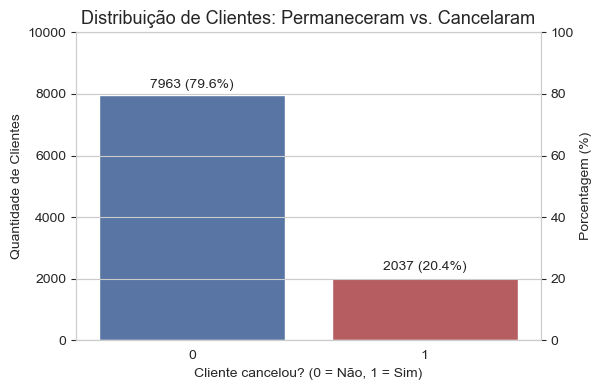

In [11]:
# Plotar informação em um gráfico
plt.figure(figsize = (6,4))
ax = sns.countplot(data = df, x = "Exited", hue = "Exited", palette = ["#4C72B0","#C44E52"], legend = False)

total = len(df)

# Criando os eixos Y do gráfico proporcionalmente
ax2 = ax.twinx() # Eixos y a esquerda e a direita compartilham o mesmo eixo x
ax2.set_ylim(0,100) # Como será percent. limita-se de 0 a 100
ax.set_ylim(0, total)

# Criando título dos gráficos e eixos
ax.set_title("Distribuição de Clientes: Permaneceram vs. Cancelaram", fontsize = 13)
ax.set_xlabel("Cliente cancelou? (0 = Não, 1 = Sim)")
ax.set_ylabel("Quantidade de Clientes")
ax2.set_ylabel("Porcentagem (%)")

for container in ax.containers:
    labels = [f"{int(v.get_height())} ({(v.get_height() / total) * 100:.1f}%)" for v in container]
    ax.bar_label(container, labels = labels, padding = 3, fontsize = 10)

plt.savefig("images/01_churn_geral.png", dpi=150, bbox_inches="tight")
plt.show()

#### Pergunta 1: Qual a taxa de churn geral?

**Insight:** Com uma taxa de churn de, aproximadamente, 20,4%, pode-se perceber que, cerca de 1 a cada 5 clientes encerrou seu relacionamento com o banco. Essa taxa serve como ponto de referência para todas as análises seguintes: qualquer subgrupo com taxa de churn acima desse valor representa um risco elevado, enquanto grupos abaixo dele indicam maior fidelização relativa. O próximo objetivo será entender quais fatores fizeram esse percentual variar entre diferentes tipos de clientes.

## Pergunta 2
#### O churn está concentrado em algum país?

In [12]:
## Calculando a média de churn por país

churn_country = df.groupby("Geography")["Exited"].mean() * 100 
churn_country

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64

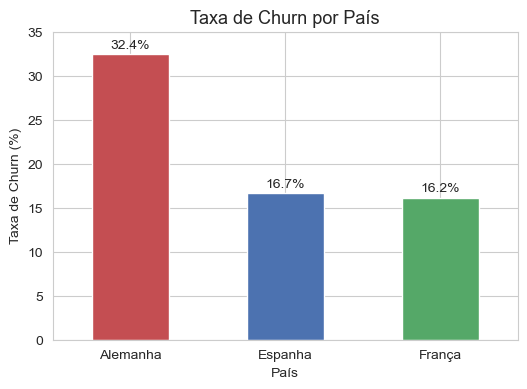

In [13]:
## Plotando o gráfico 

churn_country_pt = churn_country.rename(index={"Germany": "Alemanha", "Spain": "Espanha", "France": "França"})

plt.figure(figsize=(6,4))
ax = churn_country_pt.sort_values(ascending = False).plot(kind = "bar", color = ["#C44E52", "#4C72B0", "#55A868"])
ax.set_axisbelow(True) ## Colocando as linhas do eixo abaixo da barra

ax.set_title("Taxa de Churn por País", fontsize = 13)
ax.set_xlabel("País")
ax.set_ylabel("Taxa de Churn (%)")
ax.set_ylim(0, 35)
plt.xticks(rotation=0) ## Rotação dos nomes no eixo x

for container in ax.containers:
    labels = [f"{v.get_height():.1f}%" for v in container] ## Pega a altura de cada barra
    ax.bar_label(container, labels = labels, padding = 2) ## Coloca o rótulo na barra

plt.savefig("images/02_pais.png", dpi=150, bbox_inches="tight")    
plt.show()

#### Pergunta 2: O churn está concentrado em algum país?

**Insight:** A taxa de churn varia significativamente entre os países. A Alemanha apresenta a maior taxa de cancelamento, com 32,4%, enquanto França e Espanha têm taxas bem mais próximas entre si, em torno de 16,2% e 16,7%, respectivamente. Isso sugere que fatores específicos do mercado alemão podem estar impactando a retenção, vale investigar esse ponto mais a fundo em uma análise futura, talvez cruzando país com outras variáveis como score de crédito ou saldo.

## Pergunta 3
#### O gênero ou a idade influenciam no churn?

In [14]:
churn_gender = df.groupby("Gender")["Exited"].mean() * 100
churn_gender

Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64

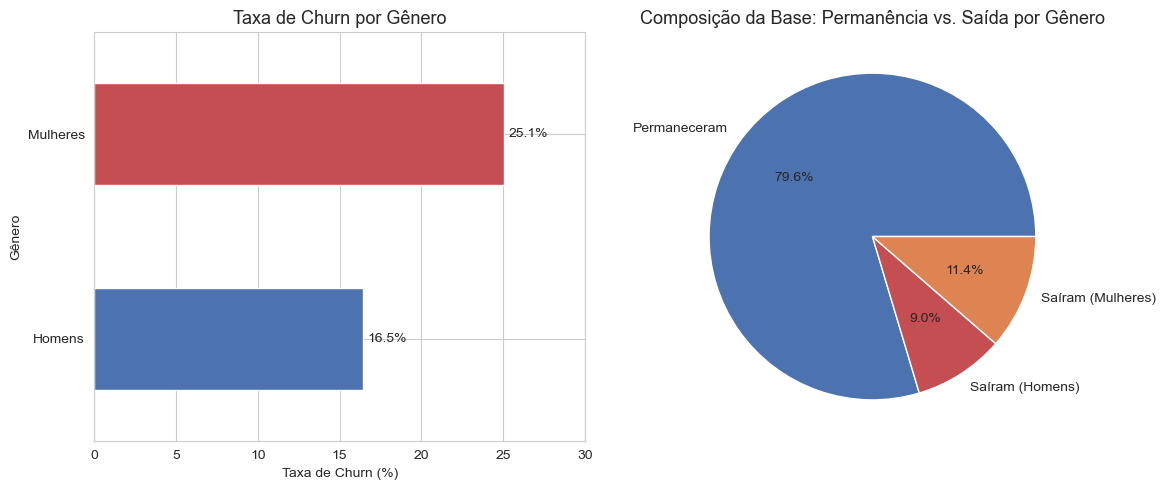

In [15]:
## Construindo um dicionário com a divisão dos grupos 

composicao_saida = pd.Series({
    "Permaneceram": (df["Exited"] == 0).sum(),
    "Saíram (Homens)": ((df["Exited"] == 1) & (df["Gender"] == "Male")).sum(),
    "Saíram (Mulheres)": ((df["Exited"] == 1) & (df["Gender"] == "Female")).sum()
})

## Criando gráfico 

churn_gender_pt = churn_gender.rename(index={"Male": "Homens", "Female": "Mulheres"})
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1 (esquerda): barra horizontal — taxa de churn por gênero
ax1 = eixos[0]
churn_gender_pt.sort_values().plot(kind="barh", color=["#4C72B0", "#C44E52"], ax=ax1)
ax1.set_axisbelow(True)
ax1.set_xlim(0, 30)
ax1.set_title("Taxa de Churn por Gênero", fontsize=13)
ax1.set_xlabel("Taxa de Churn (%)")
ax1.set_ylabel("Gênero")
for container in ax1.containers:
    labels = [f"{v.get_width():.1f}%" for v in container]
    ax1.bar_label(container, labels=labels, padding=3)

# Gráfico 2 (direita): pizza — composição da base
ax2 = eixos[1]
ax2.pie(composicao_saida, labels=composicao_saida.index, autopct="%1.1f%%", colors=["#4C72B0", "#C44E52", "#DD8452"])
ax2.set_title("Composição da Base: Permanência vs. Saída por Gênero", fontsize=13)

plt.tight_layout()
plt.show()

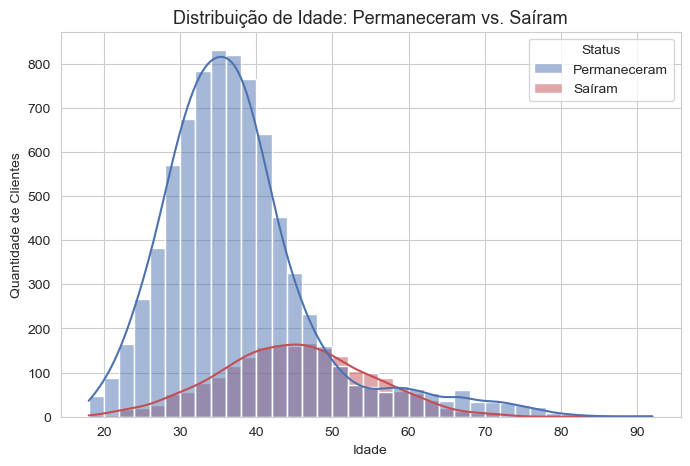

In [16]:
## Criando gráfico histograma de idade 

bins_idade = np.arange(18, 94, 2) ## Definindo o range das barras 

df["Status"] = df["Exited"].map({0: "Permaneceram", 1: "Saíram"}) ## Criando coluna de Status para substituir os 0 e 1 da coluna Exited

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Age", hue="Status", hue_order=["Permaneceram", "Saíram"], bins=bins_idade, kde=True, palette=["#4C72B0", "#C44E52"])
plt.title("Distribuição de Idade: Permaneceram vs. Saíram", fontsize=13)
plt.xlabel("Idade")
plt.ylabel("Quantidade de Clientes")

plt.savefig("images/03_idade.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
## Conferindo chrun entre clientes 50+

faixa_50_58 = df[(df["Age"] >= 50) & (df["Age"] <= 58)]

contagem_status = faixa_50_58["Exited"].value_counts()
print(contagem_status)

taxa_churn_faixa = faixa_50_58["Exited"].mean() * 100
print(f"Taxa de churn entre 50-58 anos: {taxa_churn_faixa:.1f}%")

Exited
1    457
0    350
Name: count, dtype: int64
Taxa de churn entre 50-58 anos: 56.6%


#### Pergunta 3: O gênero ou a idade influenciam no churn?

**Gênero:** Sim, há uma diferença clara entre os grupos. Mulheres apresentam uma taxa de churn de 25,1%, bem superior à dos homens (16,5%). Além disso, ao olhar a composição total da base, a proporção de mulheres que cancelaram é maior que a de homens que cancelaram — reforçando que o gênero é um fator relevante para entender o cancelamento.

**Idade:** A idade também mostra um padrão importante, mas de forma mais matizada. A base ativa do banco é composta majoritariamente por clientes entre 30 e 40 anos, esse é o "núcleo" de clientes fiéis. Já o churn se concentra mais fortemente na faixa de 40 a 50 anos, sugerindo que clientes nessa fase de vida têm maior propensão a cancelar. O achado mais chamativo, porém, está na faixa de 50 a 58 anos: nela, o número de clientes que saíram supera o número de clientes que permaneceram, um ponto de inflexão que indica que, a partir dessa idade, o banco perde mais clientes do que retém.

**Conclusão:** Tanto gênero quanto idade influenciam o churn, mas de formas diferentes: gênero indica um grupo (mulheres) com maior propensão geral ao cancelamento, enquanto idade aponta um momento específico da jornada do cliente (a partir dos 50 anos) onde a retenção falha. Combinar essas duas variáveis, por exemplo, investigar se mulheres acima de 50 anos têm a maior taxa de churn entre todos os grupos, pode ser um próximo passo interessante para aprofundar essa análise.

## **Checkpoint**

#### Resumo Parcial: Perfil Demográfico do Churn

Até aqui, a análise revela um padrão consistente: o churn não está distribuído igualmente pela base de clientes, mas concentrado em perfis específicos.

- **Taxa geral:** 20,4% dos clientes cancelaram o relacionamento com o banco.
- **País:** a Alemanha se destaca com a maior taxa de churn entre os três países analisados, indicando um problema possivelmente regional.
- **Gênero:** mulheres cancelam proporcionalmente mais que homens (25,1% vs. 16,5%).
- **Idade:** o churn se intensifica a partir dos 40 anos, atingindo seu ponto mais crítico entre 50-58 anos, faixa em que **56,6%** dos clientes cancelam, quase o triplo da taxa geral do banco.

## Pergunta 4
#### O score de crédito possui algum impacto sobre o churn?

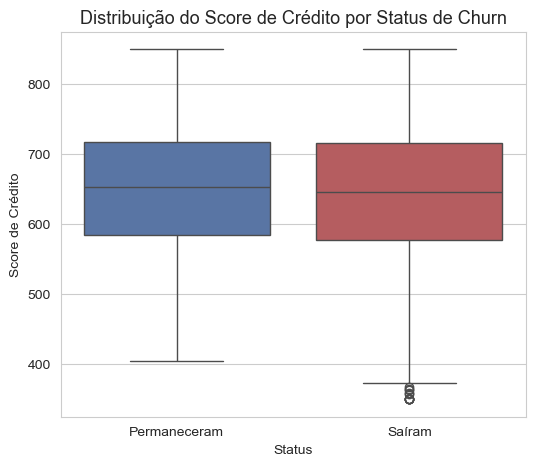

In [18]:
plt.figure(figsize=(6,5))

## Criando um gráfixo boxplot
ax = sns.boxplot(data=df, x="Status", y="CreditScore", hue="Status", order=["Permaneceram", "Saíram"], palette=["#C44E52", "#4C72B0"], legend=False)
ax.set_axisbelow(True)
ax.set_title("Distribuição do Score de Crédito por Status de Churn", fontsize=13)
ax.set_xlabel("Status")
ax.set_ylabel("Score de Crédito")
plt.show()

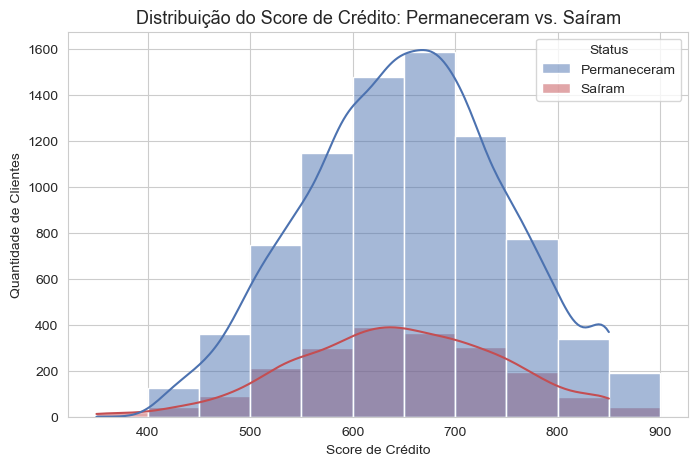

In [19]:
## Criando um histograma
bins_score = np.arange(350, 901, 50) ##Definindo o range das barras
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="CreditScore", hue="Status", hue_order=["Permaneceram", "Saíram"], bins=bins_score, kde=True, palette=["#4C72B0", "#C44E52"])
plt.title("Distribuição do Score de Crédito: Permaneceram vs. Saíram", fontsize=13)
plt.xlabel("Score de Crédito")
plt.ylabel("Quantidade de Clientes")
plt.show()

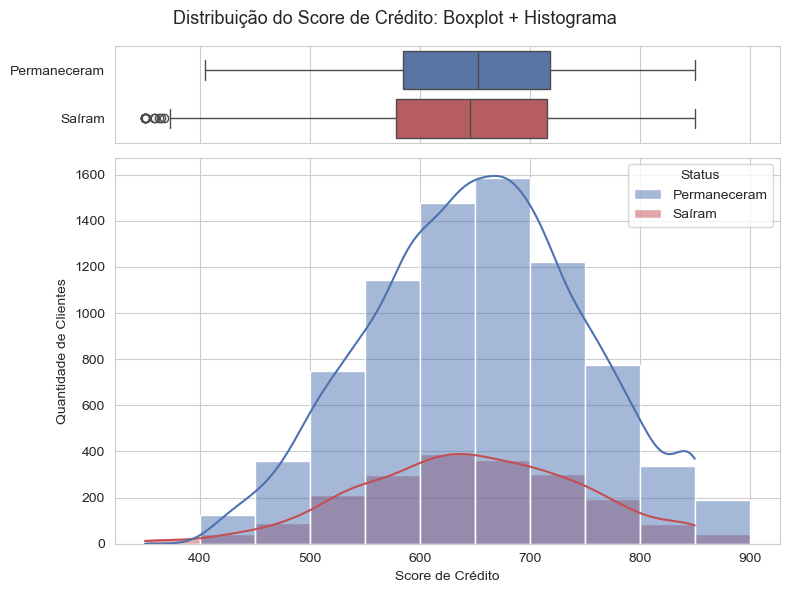

In [20]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, 
    sharex=True, 
    gridspec_kw={"height_ratios": (0.2, 0.8)}, 
    figsize=(8, 6)
)

# Gráfico de cima: boxplot horizontal
sns.boxplot(data=df, x="CreditScore", y="Status", hue="Status", order=["Permaneceram", "Saíram"],
            palette=["#C44E52", "#4C72B0"], legend=False, ax=ax_box)
# De
ax_box.set_xlabel("") 
ax_box.set_ylabel("")

# Gráfico de baixo: histograma
sns.histplot(data=df, x="CreditScore", hue="Status", hue_order=["Permaneceram", "Saíram"],
             bins=bins_score, kde=True, palette=["#4C72B0", "#C44E52"], ax=ax_hist)
ax_hist.set_xlabel("Score de Crédito")
ax_hist.set_ylabel("Quantidade de Clientes")

fig.suptitle("Distribuição do Score de Crédito: Boxplot + Histograma", fontsize=13)
plt.tight_layout()
plt.show()

In [21]:
## Conferindo a relevância dos clientes com baixo score que saíram

abaixo_400 = df[df["CreditScore"] < 400]

contagem_abaixo_400 = abaixo_400["Status"].value_counts()
print(contagem_abaixo_400)

pct_do_total = len(abaixo_400) / len(df) * 100
print(f"\nRepresentam {pct_do_total:.2f}% do total de clientes do banco")

Status
Saíram    19
Name: count, dtype: int64

Representam 0.19% do total de clientes do banco


#### Pergunta 4: O score de crédito possui algum impacto sobre o churn?

Diferente de gênero e idade, o score de crédito não mostrou influência relevante sobre o churn. Tanto o boxplot quanto o histograma revelam distribuições bastante semelhantes entre clientes que permaneceram e os que cancelaram, com medianas próximas e sobreposição significativa entre os dois grupos.

O único ponto de destaque visual foi a presença de outliers: todos os clientes com score de crédito abaixo de 400 fazem parte do grupo que cancelou. No entanto, ao investigar esse subgrupo, ele é composto por apenas 19 clientes, o equivalente a **0,19%** do total da base. Um número dessa magnitude não é suficiente para caracterizar um padrão real, e sim uma ocorrência pontual.

**Conclusão:** Logo, score de crédito, isoladamente, não parece ser um fator relevante para prever ou explicar o churn nesse dataset.

## Pergunta 5
#### Clientes com saldo mais alto tendem a sair do banco?

In [22]:
## Investigando saldo dos clientes

saldo_zero = df[df["Balance"] == 0]
saldo_positivo = df[df["Balance"] > 0]

percentual_saldo_zero = len(saldo_zero) / len(df) * 100
print(f"Clientes com saldo zero: {percentual_saldo_zero:.1f}% da base")

churn_saldo_zero = saldo_zero["Exited"].mean() * 100
churn_saldo_positivo = saldo_positivo["Exited"].mean() * 100

print(f"Taxa de churn (saldo = 0): {churn_saldo_zero:.1f}%")
print(f"Taxa de churn (saldo > 0): {churn_saldo_positivo:.1f}%")

Clientes com saldo zero: 36.2% da base
Taxa de churn (saldo = 0): 13.8%
Taxa de churn (saldo > 0): 24.1%


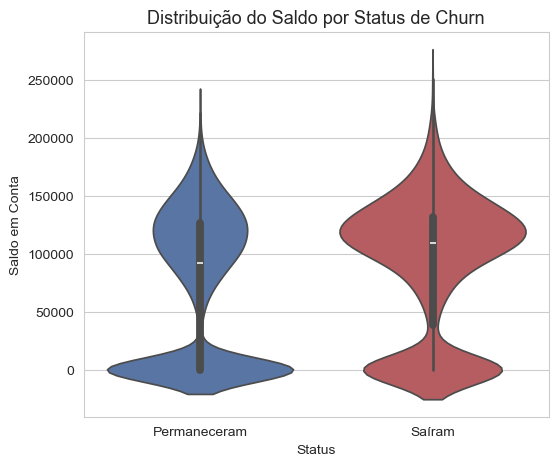

In [23]:
## Criando um gráfico violin plot

plt.figure(figsize=(6,5))
ax = sns.violinplot(data=df, x="Status", y="Balance", hue="Status", order=["Permaneceram", "Saíram"],
                     palette=["#C44E52", "#4C72B0"], legend=False)
ax.set_axisbelow(True)
ax.set_title("Distribuição do Saldo por Status de Churn", fontsize=13)
ax.set_xlabel("Status")
ax.set_ylabel("Saldo em Conta")
plt.show()

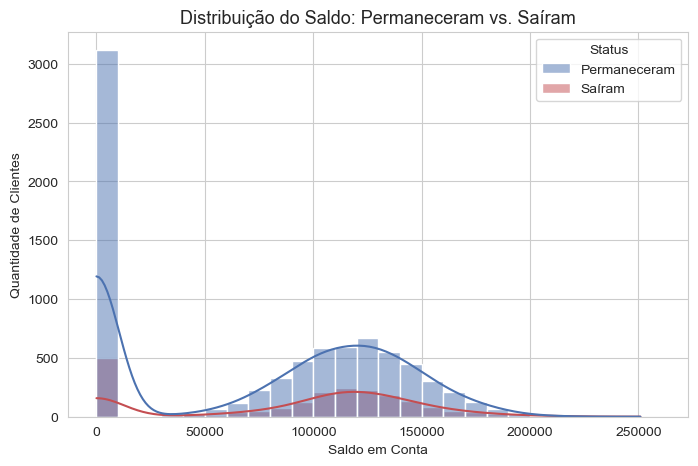

In [24]:
## Criando um histograma

bins_saldo = np.arange(0, df["Balance"].max() + 10001, 10000)

plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Balance", hue="Status", hue_order=["Permaneceram", "Saíram"],
             bins=bins_saldo, kde=True, palette=["#4C72B0", "#C44E52"])
plt.title("Distribuição do Saldo: Permaneceram vs. Saíram", fontsize=13)
plt.xlabel("Saldo em Conta")
plt.ylabel("Quantidade de Clientes")
plt.show()

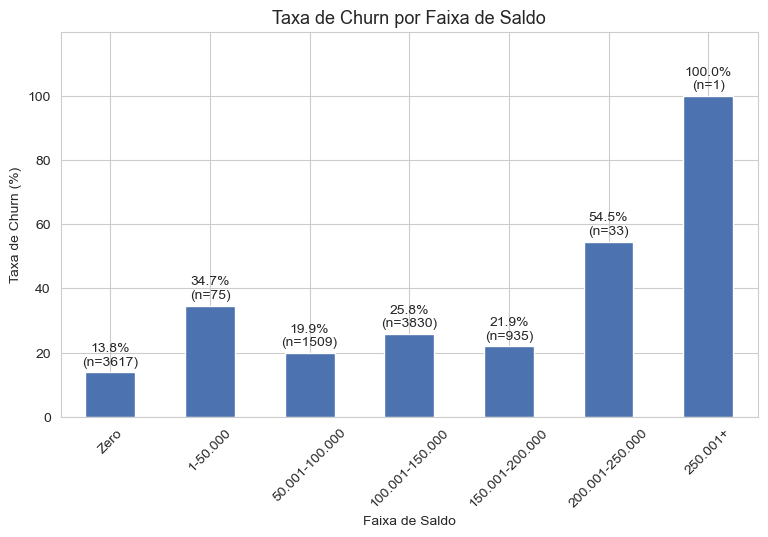

In [37]:
## Criando um gráfico de barras com faixas de saldo
limites_saldo = [-1, 0, 50000, 100000, 150000, 200000, 250000, df["Balance"].max() + 1]
rotulos_saldo = ["Zero", "1-50.000", "50.001-100.000", "100.001-150.000", "150.001-200.000", "200.001-250.000", "250.001+"]

df["FaixaSaldo"] = pd.cut(df["Balance"], bins=limites_saldo, labels=rotulos_saldo)

resumo_saldo = df.groupby("FaixaSaldo", observed=True)["Exited"].agg(["mean", "count"])
resumo_saldo["mean"] = resumo_saldo["mean"] * 100
resumo_saldo.columns = ["TaxaChurn", "TotalClientes"]

plt.figure(figsize=(9,5))
ax = resumo_saldo["TaxaChurn"].plot(kind="bar", color="#4C72B0")
ax.set_ylim(0, resumo_saldo["TaxaChurn"].max() * 1.2)   # espaço para o rótulo de duas linhas
ax.set_yticks(range(0, 101, 20))
ax.set_axisbelow(True)
ax.set_title("Taxa de Churn por Faixa de Saldo", fontsize=13)
ax.set_xlabel("Faixa de Saldo")
ax.set_ylabel("Taxa de Churn (%)")
plt.xticks(rotation=45)

rotulos = [f"{taxa:.1f}%\n(n={n})" for taxa, n in zip(resumo_saldo["TaxaChurn"], resumo_saldo["TotalClientes"])]
ax.bar_label(ax.containers[0], labels=rotulos, padding=3)

plt.savefig("images/04_saldo.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
faixa_200_250 = df[(df["Balance"] > 200000) & (df["Balance"] <= 250000)]
faixa_acima_250 = df[df["Balance"] > 250000]

print(f"Clientes entre 200.001-250.000: {len(faixa_200_250)} ({len(faixa_200_250)/len(df)*100:.2f}% do total)")
print(f"Clientes acima de 250.000: {len(faixa_acima_250)} ({len(faixa_acima_250)/len(df)*100:.2f}% do total)")

Clientes entre 200.001-250.000: 33 (0.33% do total)
Clientes acima de 250.000: 1 (0.01% do total)


#### Pergunta 5: Clientes com saldo mais alto tendem a sair do banco?

A relação entre saldo e churn se mostrou mais complexa do que uma simples correlação direta. Cerca de 36,2% dos clientes têm saldo zero em conta, provavelmente contas pouco ativas, e esse grupo apresenta a menor taxa de churn entre todos (13,8%), possivelmente porque, sem uso ativo do banco, esses clientes também não sentem necessidade de cancelar formalmente a conta.

Entre os clientes com saldo positivo, a relação não é linear: a taxa de churn sobe de 19,9% na faixa de 50.001-100.000 para 25,8% na faixa de 100.001-150.000, justamente a faixa com o maior volume de clientes (n=3.830) e de cancelamentos, e recua para 21,9% na faixa de 150.001-200.000. Isso torna a faixa de 100 a 150 mil o achado mais relevante da análise: aproximadamente 1 em cada 4 clientes nessa faixa de saldo cancela o relacionamento com o banco. A faixa de 1-50.000 tem a taxa mais alta (34,7%), mas reúne apenas 75 clientes (0,75% da base), o que torna esse número pouco confiável.

As faixas acima de 200.000 apresentam taxas de churn ainda mais altas (54,5% e 100%), mas correspondem a apenas 34 clientes no total (0,34% da base), amostras pequenas demais para sustentar conclusões robustas, funcionando mais como uma curiosidade estatística do que um padrão confiável.

**Conclusão:** o saldo influencia o churn, mas não de forma simplesmente proporcional. O maior risco de cancelamento com volume relevante de clientes está concentrado na faixa de 100k-150k, um público que provavelmente já movimenta o banco de forma significativa e tem alternativas competitivas no mercado, tornando-o prioritário para estratégias de retenção.

## **Checkpoint**

#### Resumo Parcial: Perfil Financeiro do Churn

Diferente do bloco demográfico, o perfil financeiro mostrou resultados mais desiguais: uma variável sem impacto relevante, e outra com uma relação complexa e não-linear.

- **Score de crédito:** não apresentou influência relevante sobre o churn — as distribuições entre quem ficou e quem saiu são praticamente sobrepostas, com apenas um grupo pontual de outliers (0,19% da base) associado a cancelamento.
- **Saldo:** apresenta relação não-linear com o churn. Clientes com saldo zero (36,2% da base) têm a menor taxa de cancelamento (13,8%), enquanto a faixa de 100.001-150.000 concentra o maior volume de clientes que saíram, com taxa de churn de 25,8% — aproximadamente 1 em cada 4 clientes dessa faixa cancela.

## Pergunta 6
#### Clientes inativos têm maior probabilidade de encerrar o relacionamento com o banco?

In [27]:
df["StatusAtividade"] = df["IsActiveMember"].map({0: "Inativo", 1: "Ativo"}) ## Criando uma nova coluna 

churn_atividade = df.groupby("StatusAtividade")["Exited"].mean() * 100 
churn_atividade

StatusAtividade
Ativo      14.269074
Inativo    26.850897
Name: Exited, dtype: float64

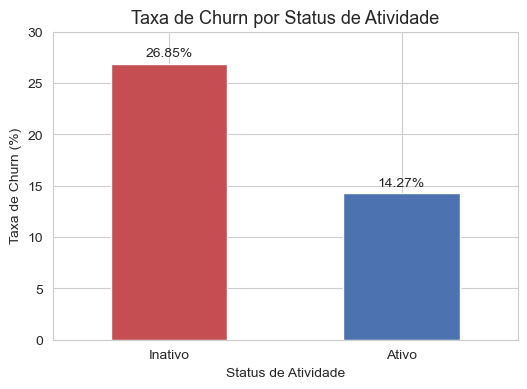

In [28]:
plt.figure(figsize=(6,4))
ax = churn_atividade.sort_values(ascending=False).plot(kind="bar", color=["#C44E52", "#4C72B0"])
ax.set_axisbelow(True)
ax.set_ylim(0, 30)
ax.set_title("Taxa de Churn por Status de Atividade", fontsize=13)
ax.set_xlabel("Status de Atividade")
ax.set_ylabel("Taxa de Churn (%)")
plt.xticks(rotation=0)
for container in ax.containers:
    labels = [f"{v.get_height():.2f}%" for v in container]
    ax.bar_label(container, labels=labels, padding=3)

plt.savefig("images/05_atividade.png", dpi=150, bbox_inches="tight") 
plt.show()

#### Pergunta 6: Clientes inativos têm maior probabilidade de encerrar o relacionamento com o banco?

Sim, e essa é uma das relações mais fortes encontradas na análise até aqui. Clientes inativos apresentam taxa de churn de 26,85%, contra apenas 14,27% entre os clientes ativos, quase o dobro. Isso reforça uma lógica intuitiva: um cliente que já não interage com o banco no dia a dia está mais próximo de formalizar o cancelamento do que um cliente engajado.

**Conclusão:** o engajamento do cliente (medido aqui pela atividade) é um dos indicadores mais consistentes de risco de churn identificados até agora, e, diferente de variáveis como idade ou país, é algo sobre o qual o banco pode agir diretamente, por meio de estratégias de reengajamento.

## Pergunta 7
#### Como é a taxa de churn em clientes com maior tempo de relacionamento (tenure)?

In [29]:
df = df.rename(columns={"Tenure": "TempoRelacionamento"})
df.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'TempoRelacionamento',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited', 'Status', 'FaixaSaldo', 'StatusAtividade'],
      dtype='object')

In [30]:
churn_tenure = df.groupby("TempoRelacionamento")["Exited"].mean() * 100
churn_tenure

TempoRelacionamento
0     23.002421
1     22.415459
2     19.179389
3     21.110010
4     20.525784
5     20.652174
6     20.268873
7     17.217899
8     19.219512
9     21.646341
10    20.612245
Name: Exited, dtype: float64

In [31]:
df["TempoRelacionamento"].value_counts().sort_index()

TempoRelacionamento
0      413
1     1035
2     1048
3     1009
4      989
5     1012
6      967
7     1028
8     1025
9      984
10     490
Name: count, dtype: int64

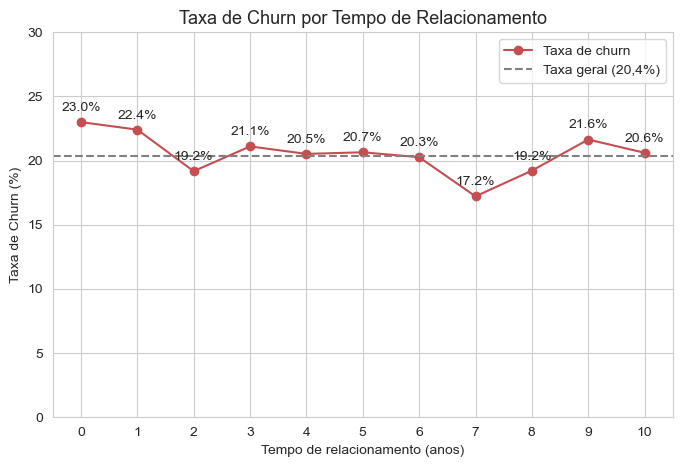

In [32]:
plt.figure(figsize=(8,5))
ax = churn_tenure.plot(kind="line", marker="o", color="#C44E52", label="Taxa de churn")
ax.set_axisbelow(True)
ax.set_ylim(0, 30)
ax.set_title("Taxa de Churn por Tempo de Relacionamento", fontsize=13)
ax.set_xlabel("Tempo de relacionamento (anos)")
ax.set_ylabel("Taxa de Churn (%)")
ax.set_xticks(range(0, 11))

# Linha de referência: taxa geral do banco
ax.axhline(20.4, color="gray", linestyle="--", label="Taxa geral (20,4%)")

# Percentual em cima de cada ponto
for x, y in zip(churn_tenure.index, churn_tenure.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")

ax.legend(loc="upper right")

plt.show()

#### Pergunta 7: Como é a taxa de churn em clientes com maior tempo de relacionamento (tenure)?

O tempo de relacionamento com o banco não mostrou relação clara com o churn. A taxa de cancelamento varia apenas entre 17,2% e 23,0% ao longo dos períodos analisados, sempre próxima da taxa geral de 20,4% e sem tendência de alta ou queda conforme o cliente fica mais tempo na base. Mesmo os anos com menos clientes (0 e 10 anos, com 413 e 490 clientes) mantêm taxas dentro dessa mesma faixa, e todos os grupos têm amostra suficiente para uma leitura confiável.

**Conclusão:** o tempo de relacionamento, isoladamente, não parece ser um fator relevante para explicar o churn: clientes novos e clientes de longa data têm risco de cancelamento semelhante, o que indica que a fidelidade não cresce automaticamente com o tempo de casa.

## Pergunta 8
#### Clientes com mais produtos cancelam menos?

In [33]:
df = df.rename(columns={"NumOfProducts": "QtdProdutos"})

In [34]:
resumo_produtos = df.groupby("QtdProdutos")["Exited"].agg(["mean", "count", "sum"])
resumo_produtos["mean"] = resumo_produtos["mean"] * 100
resumo_produtos.columns = ["TaxaChurn", "TotalClientes", "Saíram"]
resumo_produtos

,TaxaChurn,TotalClientes,Saíram
QtdProdutos,,,
1,27.714398,5084,1409
2,7.581699,4590,348
3,82.706767,266,220
4,100.000000,60,60


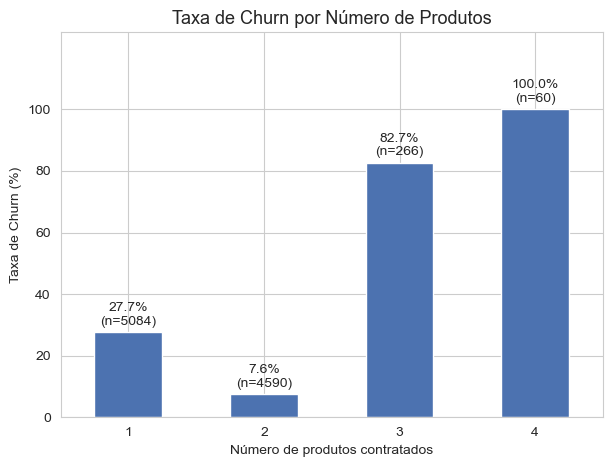

In [38]:
plt.figure(figsize=(7,5))
ax = resumo_produtos["TaxaChurn"].plot(kind="bar", color="#4C72B0")
ax.set_axisbelow(True)
ax.set_ylim(0, resumo_produtos["TaxaChurn"].max() * 1.25)
ax.set_yticks(range(0, 101, 20))
ax.set_title("Taxa de Churn por Número de Produtos", fontsize=13)
ax.set_xlabel("Número de produtos contratados")
ax.set_ylabel("Taxa de Churn (%)")
plt.xticks(rotation=0)

rotulos = [f"{taxa:.1f}%\n(n={n})" for taxa, n in zip(resumo_produtos["TaxaChurn"], resumo_produtos["TotalClientes"])]
ax.bar_label(ax.containers[0], labels=rotulos, padding=3)

plt.savefig("images/06_produtos.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
resumo_produtos["PctDasSaidas"] = resumo_produtos["Saíram"] / resumo_produtos["Saíram"].sum() * 100
resumo_produtos

,TaxaChurn,TotalClientes,Saíram,PctDasSaidas
QtdProdutos,,,,
1,27.714398,5084,1409,69.170349
2,7.581699,4590,348,17.083947
3,82.706767,266,220,10.800196
4,100.000000,60,60,2.945508


#### Pergunta 8: Clientes com mais produtos cancelam menos?

A relação entre número de produtos e churn não é linear. Clientes com 2 produtos são os mais fiéis do banco, com apenas 7,6% de cancelamento (n=4.590), bem abaixo da taxa geral de 20,4%. Clientes com apenas 1 produto cancelam bem mais (27,7%) e, por serem o maior grupo da base (n=5.084), concentram cerca de 69,2% de todas as saídas. Os clientes com 3 e 4 produtos apresentam taxas de churn muito altas (82,7% e 100%), mas representam juntos apenas 3,3% da base e cerca de 14% das saídas; por serem grupos pequenos e sem informação sobre os motivos dos cancelamentos, esse resultado merece investigação própria antes de qualquer conclusão.

**Conclusão:** ter mais produtos não garante fidelidade: o ponto de menor churn está em 2 produtos. O maior volume de perdas está entre clientes com 1 produto, o que torna esse grupo prioritário para ações de retenção, como testar a oferta de um segundo produto. A análise mostra associação, não causa: não dá para afirmar que contratar um segundo produto, por si só, reduz o risco de cancelamento.

## **Checkpoint**

#### Resumo Parcial: Perfil Comportamental do Churn

O bloco comportamental trouxe os sinais mais acionáveis para o banco: o engajamento do cliente e a quantidade de produtos mostraram relação clara com o cancelamento, enquanto o tempo de relacionamento não teve impacto relevante.

- **Atividade:** clientes inativos cancelam quase o dobro dos ativos (26,85% vs. 14,27%), indicando que o engajamento é um dos indicadores mais consistentes de risco de churn.
- **Tempo de relacionamento:** sem relação clara com o churn. A taxa varia apenas entre 17,2% e 23,0% ao longo dos 11 anos analisados, sempre próxima da taxa geral de 20,4%, o que indica que a fidelidade não cresce automaticamente com o tempo de casa.
- **Número de produtos:** a relação não é linear. Clientes com 2 produtos são os mais fiéis (7,6% de churn), enquanto os de 1 produto cancelam mais (27,7%) e concentram cerca de 69% de todas as saídas. Os grupos com 3 e 4 produtos têm taxas muito altas (82,7% e 100%), mas somam apenas 3,3% da base e merecem investigação própria.

# Conclusão Geral

### Quais fatores estão associados ao churn de clientes do banco?

Do total de 10.000 clientes, 20,4% cancelaram o relacionamento com o banco. O churn não se distribui de forma uniforme: ele se concentra em perfis específicos, e algumas variáveis mostraram pouca ou nenhuma relação com ele.

No perfil **demográfico**, a Alemanha apresenta a maior taxa de cancelamento entre os países, mulheres cancelam mais que homens (25,1% vs. 16,5%) e o risco cresce com a idade, atingindo o ponto mais crítico entre 50 e 58 anos, faixa em que 56,6% dos clientes saem. No perfil **financeiro**, o score de crédito não mostrou impacto relevante, e o saldo tem relação não linear com o churn, com o maior volume de saídas na faixa de 100 a 150 mil (25,8% de taxa). No perfil **comportamental**, que trouxe os sinais mais acionáveis, clientes inativos cancelam quase o dobro dos ativos (26,85% vs. 14,27%), clientes com apenas 1 produto concentram cerca de 69% de todas as saídas (27,7% de churn contra 7,6% para quem tem 2 produtos) e o tempo de relacionamento não teve influência relevante.

**Recomendações para o negócio:**

- **Reengajar clientes inativos**, que formam o grupo de maior risco e sobre o qual o banco pode agir diretamente, com campanhas de reativação.
- **Priorizar clientes com 1 produto**, que concentram o maior volume de perdas, testando a oferta de um segundo produto (idealmente em um teste controlado, já que a análise mostra associação e não causa).
- **Investigar os grupos de maior intensidade de churn**, como o mercado alemão, a faixa de 50 a 58 anos e os clientes com 3 ou 4 produtos, para entender o que está motivando os cancelamentos.

**Limitações e próximos passos:** as variáveis foram analisadas uma a uma, então ainda não sabemos como interagem entre si (por exemplo, se o risco elevado das mulheres se mantém dentro de cada faixa etária, ou se o efeito da inatividade muda por país). Os resultados mostram associações, não relações de causa e efeito, e vêm de um dataset público, que pode não refletir a realidade de um banco específico. Como próximos passos, vale cruzar as variáveis mais relevantes e treinar um modelo simples de classificação para medir o peso de cada fator na previsão do churn.